# GUI for Exam Schedule Plots

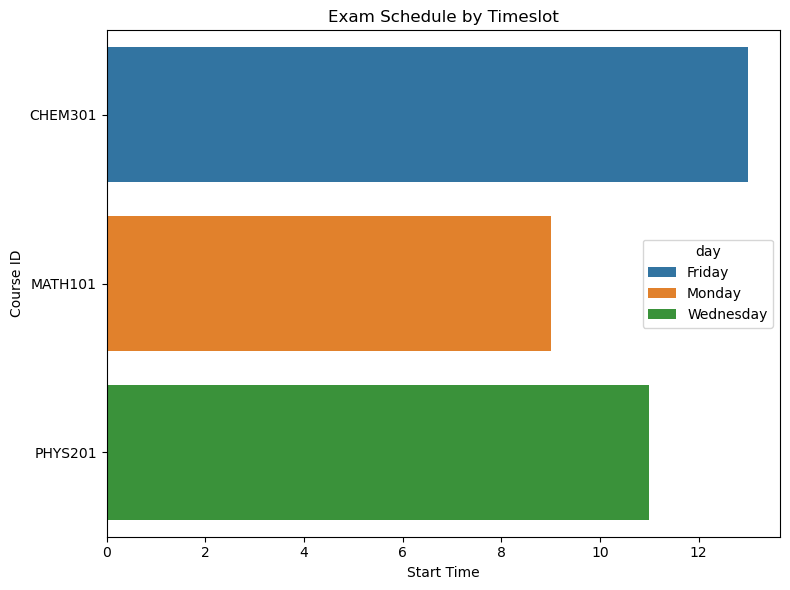

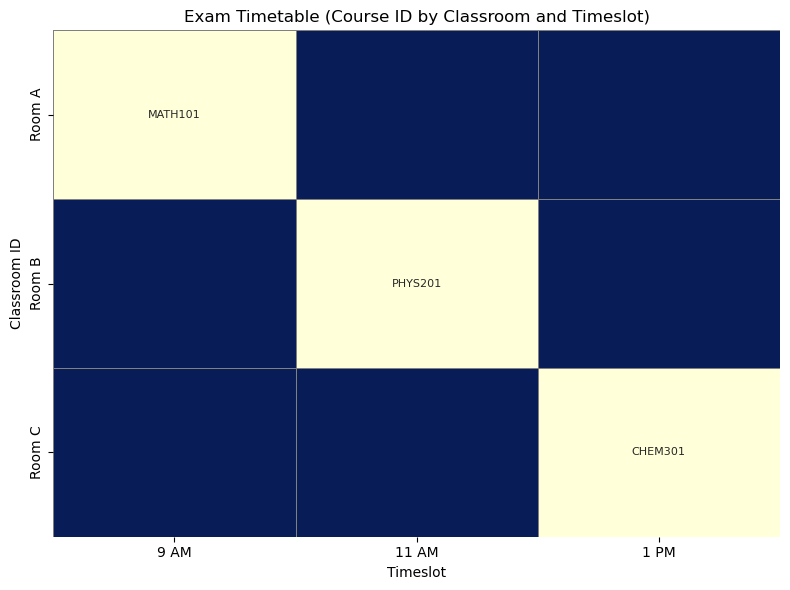

In [1]:

import tkinter as tk
from tkinter import ttk
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Dummy data structure for demonstration (replace with real data loading if needed)
final_schedule_df = pd.DataFrame({
    'course_id': ['MATH101', 'PHYS201', 'CHEM301'],
    'start_time': [9, 11, 13],
    'day': ['Monday', 'Wednesday', 'Friday']
})

# Sample timetable heatmap (replace with real timetable if available)
timetable = pd.DataFrame([
    ['MATH101', '', ''],
    ['', 'PHYS201', ''],
    ['', '', 'CHEM301']
], index=['Room A', 'Room B', 'Room C'], columns=['9 AM', '11 AM', '1 PM'])

def plot_bar(ax):
    final_schedule_df_sorted = final_schedule_df.sort_values(by=['day', 'start_time'])
    sns.barplot(
        data=final_schedule_df_sorted,
        y='course_id',
        x='start_time',
        hue='day',
        dodge=False,
        ax=ax
    )
    ax.set_title("Exam Schedule by Timeslot")
    ax.set_xlabel("Start Time")
    ax.set_ylabel("Course ID")

def plot_heatmap(ax):
    sns.heatmap(
        timetable.isin(['']),
        cbar=False,
        cmap='YlGnBu',
        linewidths=0.5,
        linecolor='gray',
        annot=timetable,
        fmt='',
        annot_kws={"size": 8},
        ax=ax
    )
    ax.set_title("Exam Timetable (Course ID by Classroom and Timeslot)")
    ax.set_xlabel("Timeslot")
    ax.set_ylabel("Classroom ID")

class PlotApp:
    def __init__(self, root):
        self.root = root
        self.root.title("Exam Plots GUI")

        self.tab_control = ttk.Notebook(root)

        self.bar_frame = ttk.Frame(self.tab_control)
        self.heatmap_frame = ttk.Frame(self.tab_control)

        self.tab_control.add(self.bar_frame, text='Bar Plot')
        self.tab_control.add(self.heatmap_frame, text='Heatmap')
        self.tab_control.pack(expand=1, fill='both')

        self.draw_plot(self.bar_frame, plot_bar)
        self.draw_plot(self.heatmap_frame, plot_heatmap)

    def draw_plot(self, frame, plot_func):
        fig, ax = plt.subplots(figsize=(8, 6))
        plot_func(ax)
        fig.tight_layout()
        canvas = FigureCanvasTkAgg(fig, master=frame)
        canvas.draw()
        canvas.get_tk_widget().pack(fill='both', expand=True)

# Launch the GUI
root = tk.Tk()
app = PlotApp(root)
root.mainloop()
